# 🚗 Ensemble Learning on Sri Lankan Car Prices (ikman.lk)

**Module hands-on project — Ensemble Learning Dashboard** · Bagging · Boosting · Stacking · Hybrid models

**Question:** *How accurately can ensemble methods predict the asking price of a car listed in Sri Lanka, and why do some ensembles beat others?*

| | |
|---|---|
| **Dataset** | 633 live car listings (new, reconditioned, imported & used) **scraped from [ikman.lk](https://ikman.lk)** (Sri Lanka's largest classifieds site) — Sri Lankan context, *not* a generic Kaggle/USA dataset |
| **Task** | Supervised regression: predict `price` (LKR) from brand, model, year, mileage, engine size, fuel, transmission, body type, condition, district and seller type |
| **Ensembles** | **Bagging** (Bagged Trees, Random Forest, Extra Trees) · **Boosting** (Gradient Boosting, XGBoost, LightGBM, CatBoost) · **Stacking** · **Hybrid** (Random Forest + ANN) |
| **Companion** | Streamlit dashboard (`app.py`) that loads the models trained here |


### Notebook map
1. Data collection & cleaning  2. Exploratory analysis  3. Features & pre-processing  4. Models (baselines → bagging → boosting → ANN → hybrid/stacking)  5. Comparison  6. *Why* did models behave this way? (bias–variance, learning curves, importances, residuals)  7. Save artefacts for the dashboard  8. Conclusions & limitations

## 1. Setup

In [1]:
import json, time, warnings, joblib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor,
                              GradientBoostingRegressor, StackingRegressor, VotingRegressor)
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
ROOT = Path(".")
DATA, MODELS = ROOT / "data", ROOT / "models"
MODELS.mkdir(exist_ok=True)
CURRENT_YEAR = 2026          # scrape date: Nov 2026
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
print("ready")

ready


## 2. Data collection & cleaning

**Source:** public car listings on ikman.lk, collected on **23 Nov 2026** with `scraper/scrape_ikman.py`
(rate-limited, only public pages that `robots.txt` allows). Each row is one *asking* price from one ad.

The scraper stores the raw ad fields as JSON-lines; below we parse the text fields (e.g. `"Rs 23,500,000"`, `"60,000 km"`, `"2,000 cc"`) into numbers and remove impossible values.

In [2]:
raw = pd.read_json(DATA / "ikman_cars_raw.jsonl", lines=True).drop_duplicates("id")
print("raw ads scraped:", len(raw))

def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[^0-9.]", "", regex=True), errors="coerce")

df = pd.DataFrame({
    "price":        to_num(raw["price_raw"]),
    "brand":        raw["brand"].str.strip(),
    "model":        raw["model"].str.strip(),
    "year":         to_num(raw["year"]),
    "condition":    raw["condition"],
    "transmission": raw["transmission"],
    "body":         raw["body"],
    "fuel":         raw["fuel"],
    "engine_cc":    to_num(raw["engine"]),
    "mileage_km":   to_num(raw["mileage"]),
    "district":     raw["area"].fillna(raw["location"]),
    "city":         raw["location"],
    "is_dealer":    raw["is_member"].fillna(False).astype(int),
})
df["brand_model"] = df["brand"] + " " + df["model"]
df.head()

raw ads scraped: 654


,price,brand,model,year,condition,transmission,body,fuel,engine_cc,mileage_km,district,city,is_dealer,brand_model
0,10750000,Toyota,Raize,2020,Used,Automatic,Hatchback,Petrol,1000,17000,Colombo,Dehiwala,1,Toyota Raize
1,8650000,Toyota,Yaris,2024,Reconditioned,Automatic,Saloon,Petrol,1000,35000,Colombo,Colombo 5,1,Toyota Yaris
2,20490000,Audi,A3,2024,Reconditioned,Automatic,Saloon,Petrol,1000,25000,Colombo,Colombo 10,1,Audi A3
3,8150000,Honda,Civic,2012,Used,Automatic,Saloon,Petrol,1600,142650,Colombo,Homagama,0,Honda Civic
4,33000000,Ford,Raptor Ranger,2025,Brand New,Automatic,SUV / 4x4,Diesel,2000,0,Colombo,Nugegoda,1,Ford Raptor Ranger


In [3]:
# ---- quality filters (each one is reported so the cleaning is transparent) ----
n0 = len(df)
steps = []
def keep(mask, name):
    global df
    before = len(df); df = df[mask].copy(); steps.append((name, before - len(df)))

keep(df.price.notna() & df.brand.notna() & df.year.notna(), "missing price / brand / year")
keep(df.year.between(1985, CURRENT_YEAR), "model year outside 1985–2026 (vintage / pre-release cars follow a different pricing logic)")
keep(df.price.between(300_000, 150_000_000), "price outside Rs 0.3M – 150M (typos / 'call for price')")
# engine of 0 / absurd cc = missing (e.g. EVs); mileage 0 on a *used* car = not entered
df.loc[~df.engine_cc.between(500, 8000), "engine_cc"] = np.nan
df.loc[(df.mileage_km <= 0) & (df.condition != "Brand New"), "mileage_km"] = np.nan
df.loc[df.mileage_km > 800_000, "mileage_km"] = np.nan
keep(df.condition.notna(), "missing condition")

print(pd.DataFrame(steps, columns=["filter", "rows removed"]).to_string(index=False))
print(f"\nrows: {n0} -> {len(df)}")
print(df.isna().mean().round(3)[lambda s: s > 0].to_string())
df.to_csv(DATA / "cars_clean.csv", index=False)

                                                                                    filter  rows removed
                                                              missing price / brand / year             0
model year outside 1985–2026 (vintage / pre-release cars follow a different pricing logic)            18
                                   price outside Rs 0.3M – 150M (typos / 'call for price')             3
                                                                         missing condition             0

rows: 654 -> 633
body          0.073
engine_cc     0.011
mileage_km    0.016


## 3. Exploratory data analysis

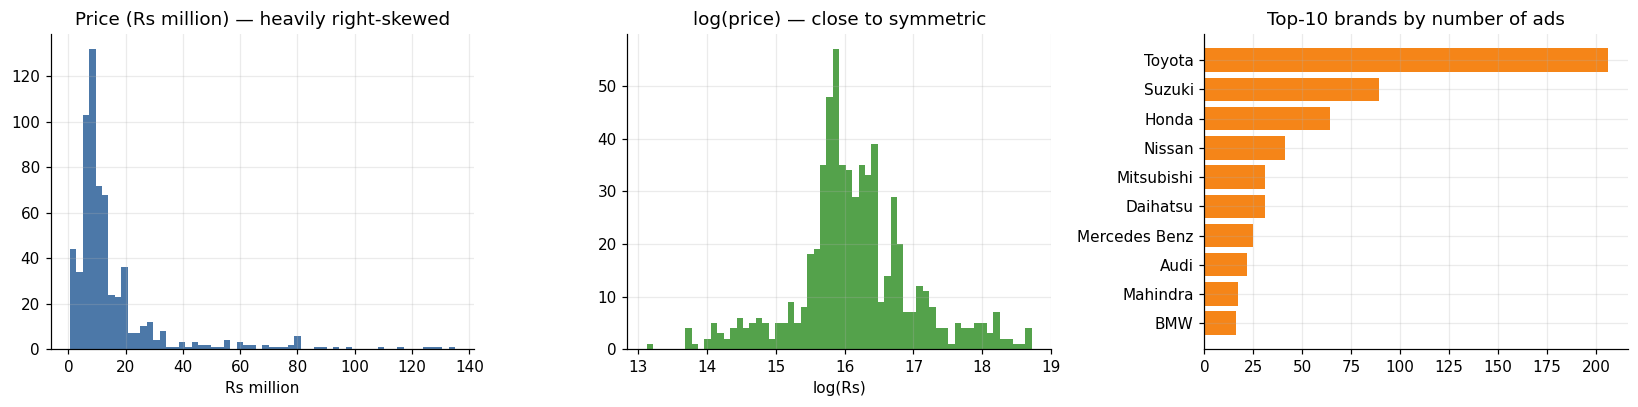

count            Rs 633
mean      Rs 15,432,190
std       Rs 18,481,481
min          Rs 500,000
25%        Rs 6,900,000
50%        Rs 9,500,000
75%       Rs 15,900,000
max      Rs 135,000,000


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(df.price / 1e6, bins=60, color="#4C78A8"); ax[0].set(title="Price (Rs million) — heavily right-skewed", xlabel="Rs million")
ax[1].hist(np.log(df.price), bins=60, color="#54A24B"); ax[1].set(title="log(price) — close to symmetric", xlabel="log(Rs)")
top = df.brand.value_counts().head(10)
ax[2].barh(top.index[::-1], top.values[::-1], color="#F58518"); ax[2].set(title="Top-10 brands by number of ads")
plt.tight_layout(); plt.show()
print(df.price.describe().apply(lambda v: f"Rs {v:,.0f}").to_string())

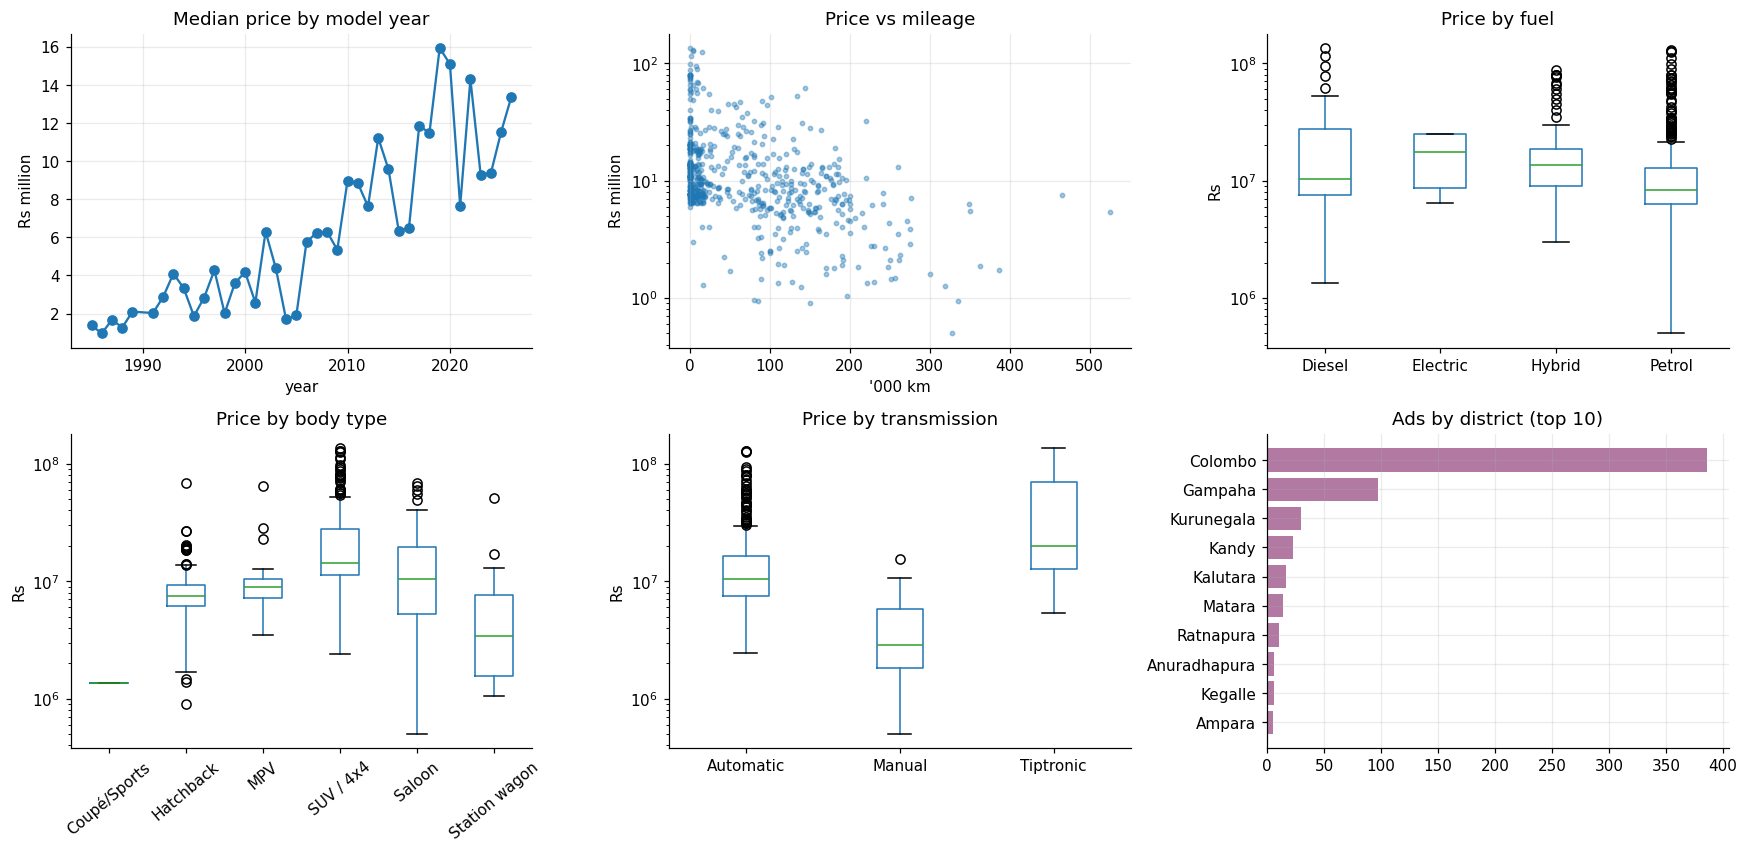

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
g = df.groupby("year").price.median() / 1e6
ax[0,0].plot(g.index, g.values, "o-"); ax[0,0].set(title="Median price by model year", xlabel="year", ylabel="Rs million")
s = df.dropna(subset=["mileage_km"]).sample(min(1500, df.mileage_km.notna().sum()), random_state=SEED)
ax[0,1].scatter(s.mileage_km / 1e3, s.price / 1e6, s=8, alpha=.4); ax[0,1].set(title="Price vs mileage", xlabel="'000 km", ylabel="Rs million", yscale="log")
df.boxplot(column="price", by="fuel", ax=ax[0,2], grid=False); ax[0,2].set(title="Price by fuel", yscale="log", xlabel="", ylabel="Rs"); ax[0,2].figure.suptitle("")
df.boxplot(column="price", by="body", ax=ax[1,0], grid=False, rot=40); ax[1,0].set(title="Price by body type", yscale="log", xlabel="", ylabel="Rs"); ax[1,0].figure.suptitle("")
df.boxplot(column="price", by="transmission", ax=ax[1,1], grid=False); ax[1,1].set(title="Price by transmission", yscale="log", xlabel="", ylabel="Rs"); ax[1,1].figure.suptitle("")
d = df.district.value_counts().head(10)
ax[1,2].barh(d.index[::-1], d.values[::-1], color="#B279A2"); ax[1,2].set(title="Ads by district (top 10)")
plt.tight_layout(); plt.show()

**What the data says**
* Prices are strongly right-skewed (median **Rs 9.5 M**, mean Rs 15.4 M, max Rs 135 M), which is why we model `log(price)`.
* The sample is a mix of **Used (331), Brand New (159), Reconditioned (102) and Import (41)** cars; **Petrol 406, Hybrid 147, Diesel 74, Electric 6**.
* Median price by condition: Brand New Rs 13.5 M · Import Rs 13.0 M · Reconditioned Rs 8.7 M · Used Rs 7.9 M. By fuel: Electric Rs 17.4 M · Hybrid Rs 13.5 M · Diesel Rs 10.3 M · Petrol Rs 8.3 M.
* Transmission is a **proxy for market segment**: median price is Rs 2.9 M for Manual, Rs 10.5 M for Automatic and Rs 19.9 M for Tiptronic — and Tiptronic cars are mostly 2025–26 imports (median year 2025) while Manual cars are mostly older (median 2005). Keep this in mind when reading the importance chart later.
* Price falls with age and rises with engine size; mileage is partly redundant with age (and is 0 for brand-new cars).

## 4. Features, target & pre-processing

* **Target:** `log(price)`. Prices span two orders of magnitude (Rs 1M city cars → Rs 100M+ luxury SUVs); modelling the log makes errors *relative* (a 10 % miss is equally bad on a Rs 3M car and a Rs 30M car) and stabilises variance. Predictions are converted back with `exp()`.
* **Engineered features:** `age = 2026 − year`, `km_per_year = mileage / max(age,1)` (usage intensity), `log_mileage`.
* **Categoricals** (`brand_model`, `brand`, `body`, `fuel`, `transmission`, `condition`, `district`) are one-hot encoded; categories seen < 8 times are grouped as "infrequent" so the models don't memorise one-off listings, and unseen categories at prediction time are ignored safely.
* **Numerics** are median-imputed (with a "was missing" flag, because a missing mileage is itself informative) and standardised (needed by the ANN / Ridge, harmless for trees).
* A single `ColumnTransformer` lives **inside every model pipeline**, so cross-validation never leaks test-fold statistics.

In [6]:
df["age"] = (CURRENT_YEAR - df.year).clip(lower=0)
df["km_per_year"] = df.mileage_km / df.age.clip(lower=1)
df["log_mileage"] = np.log1p(df.mileage_km)

NUM = ["age", "mileage_km", "engine_cc", "km_per_year", "log_mileage"]
CAT = ["brand_model", "brand", "body", "fuel", "transmission", "condition", "district"]
BIN = ["is_dealer"]
FEATURES = NUM + CAT + BIN

X, y = df[FEATURES], np.log(df.price)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("train:", X_train.shape, " test:", X_test.shape)

def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=8, sparse_output=False))]), CAT),
        ("bin", "passthrough", BIN),
    ])

def make(model):
    return Pipeline([("pre", make_pre()), ("model", model)])

print("encoded feature count:", make_pre().fit(X_train).get_feature_names_out().shape[0])

train: (506, 13)  test: (127, 13)
encoded feature count: 64


## 5. Models

We evaluate each model two ways, both on **log-price**:

1. **5-fold cross-validation on the training set** (mean ± std of RMSE) — a stable estimate we can use for choosing models.
2. **Held-out test set (20 %)** — touched once, for the final numbers. We also report test **MAE in Rupees**, **MAPE** and **R²**, plus the **train RMSE** so we can see over-fitting (the train/test gap).

Hyper-parameters are sensible, lightly-tuned defaults (no heavy search) so that the comparison reflects the *algorithms*, not tuning effort.

In [7]:
dt = DecisionTreeRegressor(min_samples_leaf=2, random_state=SEED)

base = {
    "Ridge (linear baseline)": Ridge(alpha=3.0),
    "Decision Tree (single)":  dt,
}
bagging = {
    "Bagged Trees":   BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=2), n_estimators=300, max_samples=0.8,
                                       n_jobs=-1, random_state=SEED),
    "Random Forest":  RandomForestRegressor(n_estimators=500, max_features=0.35, min_samples_leaf=1, n_jobs=-1, random_state=SEED),
    "Extra Trees":    ExtraTreesRegressor(n_estimators=500, max_features=0.5, min_samples_leaf=1, n_jobs=-1, random_state=SEED),
}
boosting = {
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=600, learning_rate=0.04, max_depth=4, subsample=0.8, random_state=SEED),
    "XGBoost":  XGBRegressor(n_estimators=700, learning_rate=0.04, max_depth=5, subsample=0.8, colsample_bytree=0.6,
                             reg_lambda=2.0, n_jobs=-1, random_state=SEED, verbosity=0),
    "LightGBM": LGBMRegressor(n_estimators=700, learning_rate=0.04, num_leaves=31, min_child_samples=10, subsample=0.8,
                              subsample_freq=1, colsample_bytree=0.6, reg_lambda=2.0, random_state=SEED, verbose=-1, n_jobs=-1),
    "CatBoost": CatBoostRegressor(iterations=1000, learning_rate=0.05, depth=6, l2_leaf_reg=3, random_seed=SEED, verbose=0, thread_count=-1),
}
neural = {
    "ANN (MLP)": MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-2, learning_rate_init=1e-3, early_stopping=True,
                              validation_fraction=0.15, n_iter_no_change=25, max_iter=1000, random_state=SEED),
}
print(len(base) + len(bagging) + len(boosting) + len(neural), "single models defined")

10 single models defined


### 5.1 Hybrid & stacking ensembles

* **Hybrid: Random Forest + ANN** — the lecture's "RF with ANN for tabular regression" idea. The forest captures sharp, rule-like structure (brand × age interactions); the neural network captures smooth trends. Their predictions are averaged (`VotingRegressor`), which only helps if their *errors differ*.
* **Stacking** — five diverse level-0 learners (Random Forest, Extra Trees, LightGBM, CatBoost, ANN) produce **out-of-fold** predictions; a Ridge **meta-learner** learns how much to trust each one. Using out-of-fold predictions prevents the meta-learner from simply trusting whichever base model over-fits the training data most.

In [8]:
def mk(name):
    pool = {**base, **bagging, **boosting, **neural}
    from sklearn.base import clone
    return make(clone(pool[name]))

hybrid_rf_ann = VotingRegressor([("rf", mk("Random Forest")), ("ann", mk("ANN (MLP)"))], n_jobs=1)

stacking = StackingRegressor(
    estimators=[("rf", mk("Random Forest")), ("et", mk("Extra Trees")), ("lgbm", mk("LightGBM")),
                ("cat", mk("CatBoost")), ("ann", mk("ANN (MLP)"))],
    final_estimator=RidgeCV(alphas=np.logspace(-3, 2, 20)),
    cv=5, n_jobs=1, passthrough=False)

ALL = {}
for group, d in [("Baseline", base), ("Bagging", bagging), ("Boosting", boosting), ("Neural", neural)]:
    for n in d: ALL[n] = (group, mk(n))
ALL["Hybrid: RF + ANN (avg)"] = ("Hybrid", hybrid_rf_ann)
ALL["Stacking (5 models → Ridge)"] = ("Stacking", stacking)
list(ALL)

['Ridge (linear baseline)',
 'Decision Tree (single)',
 'Bagged Trees',
 'Random Forest',
 'Extra Trees',
 'Gradient Boosting',
 'XGBoost',
 'LightGBM',
 'CatBoost',
 'ANN (MLP)',
 'Hybrid: RF + ANN (avg)',
 'Stacking (5 models → Ridge)']

In [9]:
kf = KFold(5, shuffle=True, random_state=SEED)
rows, fitted, preds = [], {}, {}

def mape(a, b): return float(np.mean(np.abs(a - b) / a)) * 100

for name, (group, est) in ALL.items():
    t0 = time.time()
    cv = cross_validate(est, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=1)
    cv_rmse = -cv["test_score"]
    est.fit(X_train, y_train)
    fit_s = time.time() - t0
    p_te, p_tr = est.predict(X_test), est.predict(X_train)
    price_te, price_pred = np.exp(y_test), np.exp(p_te)
    rows.append({
        "model": name, "family": group,
        "cv_rmse_mean": cv_rmse.mean(), "cv_rmse_std": cv_rmse.std(),
        "train_rmse": np.sqrt(mean_squared_error(y_train, p_tr)),
        "test_rmse": np.sqrt(mean_squared_error(y_test, p_te)),
        "test_r2": r2_score(y_test, p_te),
        "test_mae_lkr": mean_absolute_error(price_te, price_pred),
        "test_mape_pct": mape(price_te.values, price_pred),
        "seconds": fit_s,
    })
    fitted[name], preds[name] = est, p_te
    print(f"{name:32s} cv {cv_rmse.mean():.4f}±{cv_rmse.std():.4f} | test {rows[-1]['test_rmse']:.4f} | R² {rows[-1]['test_r2']:.3f} | {fit_s:5.1f}s")

results = pd.DataFrame(rows).sort_values("test_rmse").reset_index(drop=True)

Ridge (linear baseline)          cv 0.3095±0.0163 | test 0.3036 | R² 0.895 |   0.1s
Decision Tree (single)           cv 0.3626±0.0433 | test 0.3744 | R² 0.840 |   0.1s


Bagged Trees                     cv 0.2735±0.0329 | test 0.3155 | R² 0.887 |   4.2s


Random Forest                    cv 0.2729±0.0326 | test 0.2931 | R² 0.902 |   2.0s


Extra Trees                      cv 0.2725±0.0383 | test 0.2696 | R² 0.917 |   1.4s


Gradient Boosting                cv 0.2529±0.0300 | test 0.2815 | R² 0.910 |   2.6s


XGBoost                          cv 0.2626±0.0240 | test 0.2706 | R² 0.917 |   4.4s


LightGBM                         cv 0.2707±0.0281 | test 0.2888 | R² 0.905 |  12.3s


CatBoost                         cv 0.2512±0.0383 | test 0.2720 | R² 0.916 |   7.0s


ANN (MLP)                        cv 0.3870±0.0153 | test 0.4128 | R² 0.806 |   7.3s


Hybrid: RF + ANN (avg)           cv 0.2847±0.0197 | test 0.3102 | R² 0.891 |   7.3s


Stacking (5 models → Ridge)      cv 0.2474±0.0297 | test 0.2704 | R² 0.917 | 148.9s


## 6. Model comparison

In [10]:
show = results.copy()
show["train→test gap"] = show.test_rmse - show.train_rmse
show["CV RMSE"] = show.cv_rmse_mean.round(4).astype(str) + " ± " + show.cv_rmse_std.round(4).astype(str)
display(show[["model", "family", "CV RMSE", "test_rmse", "test_r2", "test_mae_lkr", "test_mape_pct", "train_rmse", "train→test gap", "seconds"]]
        .round({"test_rmse": 4, "test_r2": 3, "test_mae_lkr": 0, "test_mape_pct": 1, "train_rmse": 4, "train→test gap": 4, "seconds": 1})
        .style.format({"test_mae_lkr": "Rs {:,.0f}"}).background_gradient(subset=["test_rmse"], cmap="RdYlGn_r"))

,model,family,CV RMSE,test_rmse,test_r2,test_mae_lkr,test_mape_pct,train_rmse,train→test gap,seconds
0,Extra Trees,Bagging,0.2725 ± 0.0383,0.269600,0.917000,"Rs 2,594,762",16.700000,0.003900,0.265700,1.400000
1,Stacking (5 models → Ridge),Stacking,0.2474 ± 0.0297,0.270400,0.917000,"Rs 2,710,912",18.500000,0.062500,0.207900,148.900000
2,XGBoost,Boosting,0.2626 ± 0.024,0.270600,0.917000,"Rs 2,223,642",18.900000,0.032200,0.238500,4.400000
3,CatBoost,Boosting,0.2512 ± 0.0383,0.272000,0.916000,"Rs 2,482,478",18.600000,0.041000,0.231000,7.000000
4,Gradient Boosting,Boosting,0.2529 ± 0.03,0.281500,0.910000,"Rs 2,486,276",19.400000,0.046500,0.235000,2.600000
5,LightGBM,Boosting,0.2707 ± 0.0281,0.288800,0.905000,"Rs 2,903,434",19.700000,0.048100,0.240600,12.300000
6,Random Forest,Bagging,0.2729 ± 0.0326,0.293100,0.902000,"Rs 2,850,306",20.100000,0.093500,0.199600,2.000000
7,Ridge (linear baseline),Baseline,0.3095 ± 0.0163,0.303600,0.895000,"Rs 3,399,755",23.500000,0.248800,0.054800,0.100000
8,Hybrid: RF + ANN (avg),Hybrid,0.2847 ± 0.0197,0.310200,0.891000,"Rs 2,881,028",23.100000,0.098100,0.212100,7.300000
9,Bagged Trees,Bagging,0.2735 ± 0.0329,0.315500,0.887000,"Rs 3,014,274",21.900000,0.147400,0.168100,4.200000


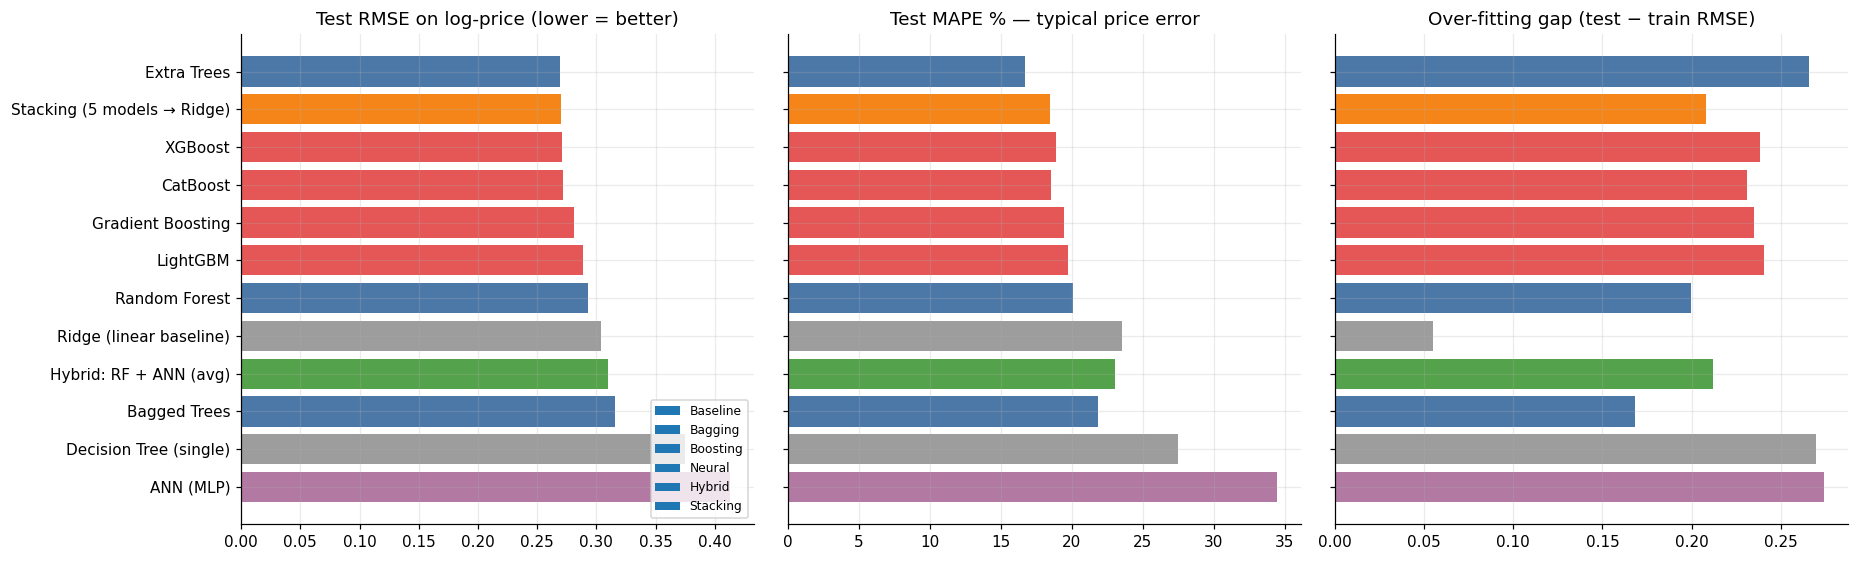

In [11]:
colors = {"Baseline": "#9D9D9D", "Bagging": "#4C78A8", "Boosting": "#E45756", "Neural": "#B279A2", "Hybrid": "#54A24B", "Stacking": "#F58518"}
r = results.sort_values("test_rmse", ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
ax[0].barh(r.model, r.test_rmse, color=[colors[f] for f in r.family]); ax[0].set(title="Test RMSE on log-price (lower = better)")
ax[1].barh(r.model, r.test_mape_pct, color=[colors[f] for f in r.family]); ax[1].set(title="Test MAPE % — typical price error"); ax[1].set_yticklabels([])
ax[2].barh(r.model, r.test_rmse - r.train_rmse, color=[colors[f] for f in r.family]); ax[2].set(title="Over-fitting gap (test − train RMSE)"); ax[2].set_yticklabels([])
for f, c in colors.items(): ax[0].barh([], [], color=c, label=f)
ax[0].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### Reading the table
* **Ensembles clearly beat a single tree.** The lone Decision Tree has test RMSE 0.374; every bagging/boosting model reaches 0.27–0.29 — roughly **25–28 % lower error**. Even the Ridge baseline (0.304) beats the single tree: prices fall multiplicatively with age, which a log-linear model captures well, while one tree is too noisy.
* **The top four are a statistical tie.** Extra Trees (0.270), Stacking (0.270), XGBoost (0.271) and CatBoost (0.272) differ by 0.002, while the cross-validation standard deviation is ≈ 0.03 and the test set has only 127 cars. We cannot honestly say one is better. Cross-validation (more data per estimate) slightly favours **Stacking (0.247)**, CatBoost (0.251) and Gradient Boosting (0.253); on rupee error **XGBoost is best (MAE ≈ Rs 2.2 M)**, i.e. it handles the expensive cars best.
* **The family matters less than the ensembling itself.** Bagging (Extra Trees 0.270 / Random Forest 0.293), boosting (0.271–0.289) and stacking (0.270) all land in the same band.
* **Extra Trees' train RMSE is 0.004** — it memorises the training set — yet it is among the best on test. A large train–test gap does not by itself mean a bad model when the members are averaged; this is why we choose by cross-validation / test error, not by the gap.
* **The ANN is the weakest model (0.413)** and the **Hybrid RF + ANN (0.310) is *worse* than Random Forest alone (0.293)**. With only ~500 training rows a neural net cannot learn the fine brand/model structure, and a plain 50/50 average hands half the vote to a much weaker member (see 7.3).
* Model-selection caveat: we report test error for the top model after seeing it, which is slightly optimistic; the CV column is the unbiased guide.

## 7. *Why* did the models behave this way?

The brief asks us to interpret results, not just report them. We use four lenses.

### 7.1 Bagging reduces **variance** — error vs number of trees
A single deep tree has low bias but very high variance (it memorises noise). Averaging many trees trained on different bootstrap samples cancels part of that noise. The curve below is the Random Forest's test error as we add trees.

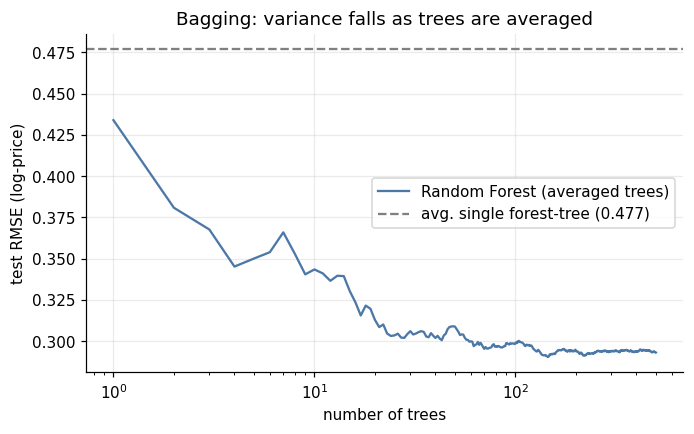

1 tree: 0.4339  →  10 trees: 0.3434  →  500 trees: 0.2931


In [12]:
rf_pipe = fitted["Random Forest"]
Xte_t = rf_pipe.named_steps["pre"].transform(X_test)
tree_preds = np.array([t.predict(Xte_t) for t in rf_pipe.named_steps["model"].estimators_])
cum = np.cumsum(tree_preds, axis=0) / np.arange(1, len(tree_preds) + 1)[:, None]
rf_curve = [np.sqrt(mean_squared_error(y_test, c)) for c in cum]
single_tree_rmse = float(np.mean([np.sqrt(mean_squared_error(y_test, p)) for p in tree_preds]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(rf_curve) + 1), rf_curve, color="#4C78A8", label="Random Forest (averaged trees)")
ax.axhline(single_tree_rmse, ls="--", color="grey", label=f"avg. single forest-tree ({single_tree_rmse:.3f})")
ax.set(xlabel="number of trees", ylabel="test RMSE (log-price)", title="Bagging: variance falls as trees are averaged", xscale="log"); ax.legend()
plt.show()
print(f"1 tree: {rf_curve[0]:.4f}  →  10 trees: {rf_curve[9]:.4f}  →  {len(rf_curve)} trees: {rf_curve[-1]:.4f}")

### 7.2 Boosting reduces **bias** — error vs boosting rounds
Boosting builds shallow trees *sequentially*, each fitted to the residual errors of the ensemble so far. Early rounds fix big, systematic errors (bias); too many rounds start fitting noise. The staged curve shows both phases.

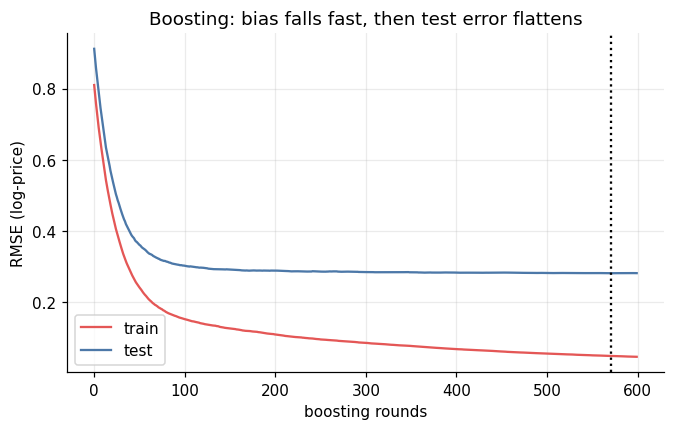

best test RMSE 0.2813 at round 571; final 0.2815; train 0.0465


In [13]:
gb_pipe = fitted["Gradient Boosting"]
Xte_t = gb_pipe.named_steps["pre"].transform(X_test); Xtr_t = gb_pipe.named_steps["pre"].transform(X_train)
gbm = gb_pipe.named_steps["model"]
te_curve = [np.sqrt(mean_squared_error(y_test, p)) for p in gbm.staged_predict(Xte_t)]
tr_curve = [np.sqrt(mean_squared_error(y_train, p)) for p in gbm.staged_predict(Xtr_t)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tr_curve, label="train", color="#E45756"); ax.plot(te_curve, label="test", color="#4C78A8")
ax.axvline(int(np.argmin(te_curve)), ls=":", color="k");
ax.set(xlabel="boosting rounds", ylabel="RMSE (log-price)", title="Boosting: bias falls fast, then test error flattens"); ax.legend(); plt.show()
print(f"best test RMSE {min(te_curve):.4f} at round {int(np.argmin(te_curve))}; final {te_curve[-1]:.4f}; train {tr_curve[-1]:.4f}")

### 7.3 Do the ensembles make *different* mistakes? (the key to stacking)
Ensembling only helps when members' errors are not perfectly correlated. Below: correlation of test residuals between models.

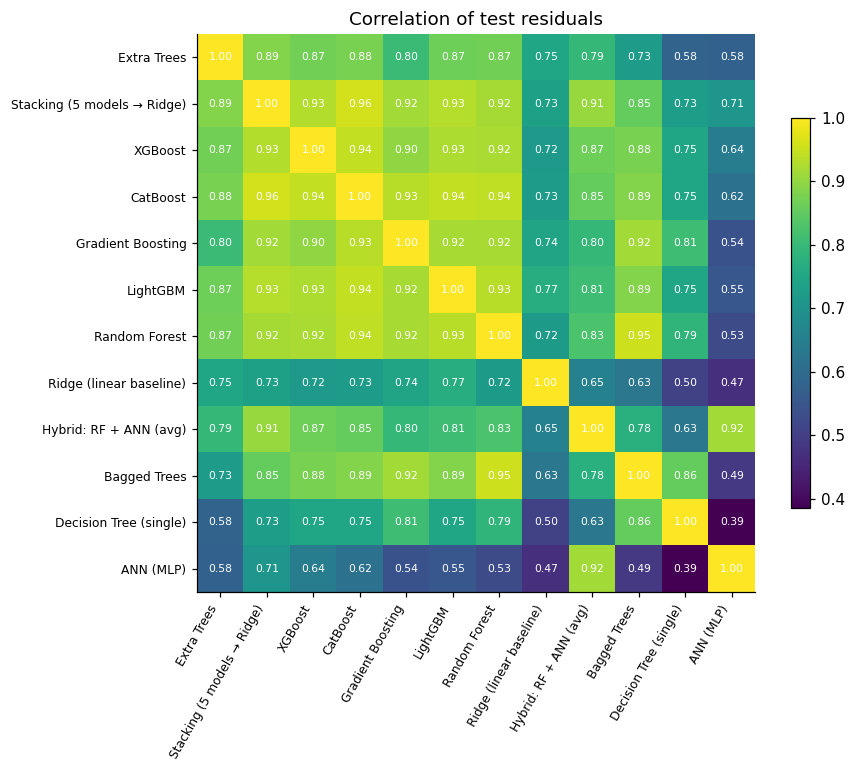

In [14]:
res = pd.DataFrame({n: (y_test.values - p) for n, p in preds.items()})
order = results.model.tolist()
corr = res[order].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="viridis", vmin=corr.values.min(), vmax=1)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8); ax.grid(False)
for i in range(len(order)):
    for j in range(len(order)): ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", color="w", fontsize=7)
plt.colorbar(im, shrink=.7); ax.set_title("Correlation of test residuals"); plt.tight_layout(); plt.show()

**Interpretation**
* The tree ensembles make **almost the same mistakes**: residual correlation is **0.90–0.94** between Random Forest, XGBoost, LightGBM, CatBoost and Gradient Boosting, and 0.96 between CatBoost and the stack. They see the same features and the same 506 training cars, so their errors are the same unlucky cars (rare models, odd listings). Averaging near-identical errors removes little — which is why **stacking improves CV error only slightly (0.247 vs 0.251 for CatBoost) and ties on the test set**.
* Extra Trees is the most "different" tree model (0.80–0.88 against the forest/boosting models) because its random split thresholds add extra smoothing — a reason it does so well on small data.
* The **ANN is the most diverse model (residual correlation 0.53–0.64) but also the least accurate**. Diversity only pays if members are individually good. The stack's Ridge meta-learner can down-weight the ANN, whereas the fixed 50/50 hybrid cannot — which explains why stacking ≥ best member but the hybrid < Random Forest.

### 7.4 What drives price? (permutation importance on the best model)
Permutation importance shuffles one *original* column at a time and measures how much test RMSE worsens — it works for any model and groups one-hot columns back into the feature they came from.

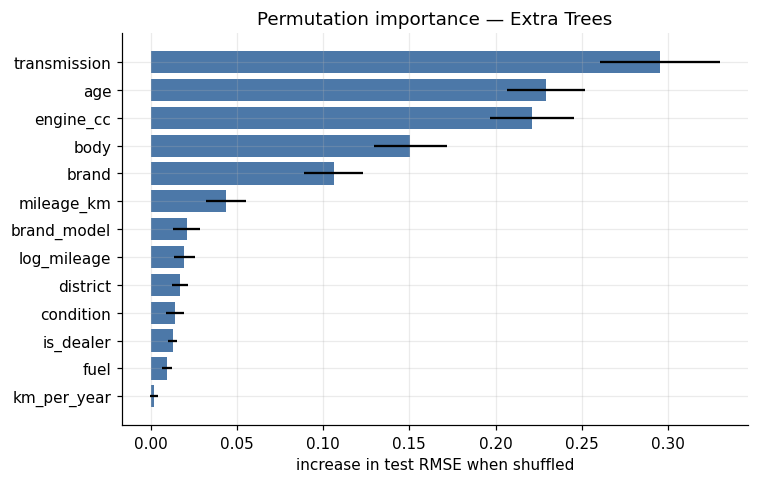

,feature,importance,std
9,transmission,0.2952,0.0348
0,age,0.2294,0.0228
2,engine_cc,0.2213,0.0244
7,body,0.1507,0.0210
6,brand,0.1062,0.0172
1,mileage_km,0.0437,0.0115
5,brand_model,0.0210,0.0078
4,log_mileage,0.0195,0.0062
11,district,0.0170,0.0046
10,condition,0.0142,0.0052


In [15]:
best_name = results.iloc[0].model
best = fitted[best_name]
pi = permutation_importance(best, X_test, y_test, n_repeats=15, random_state=SEED, scoring="neg_root_mean_squared_error", n_jobs=1)
imp = pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.feature, imp.importance, xerr=imp["std"], color="#4C78A8")
ax.set(title=f"Permutation importance — {best_name}", xlabel="increase in test RMSE when shuffled"); plt.tight_layout(); plt.show()
imp.sort_values("importance", ascending=False).round(4)

**Interpretation (Extra Trees)** — shuffling `transmission` hurts most (+0.30 RMSE), then `age` (+0.23), `engine_cc` (+0.22), `body` (+0.15) and `brand` (+0.11); `mileage_km` adds +0.04, `fuel` only +0.01.

Be careful: this is **not** "transmission causes price". Transmission, engine size, body type, fuel and age are strongly correlated with one another (new Tiptronic hybrid SUVs vs old manual hatchbacks), so the model uses transmission as a compact label for *market segment*, and permutation importance gives it the credit. Correlated features also **split** importance — `fuel` looks unimportant partly because hybrids are already identified by engine/transmission/age. Mileage matters less than age because age explains most of the depreciation and brand-new cars all have 0 km.

### 7.5 Where does the best model go wrong? (residual analysis)

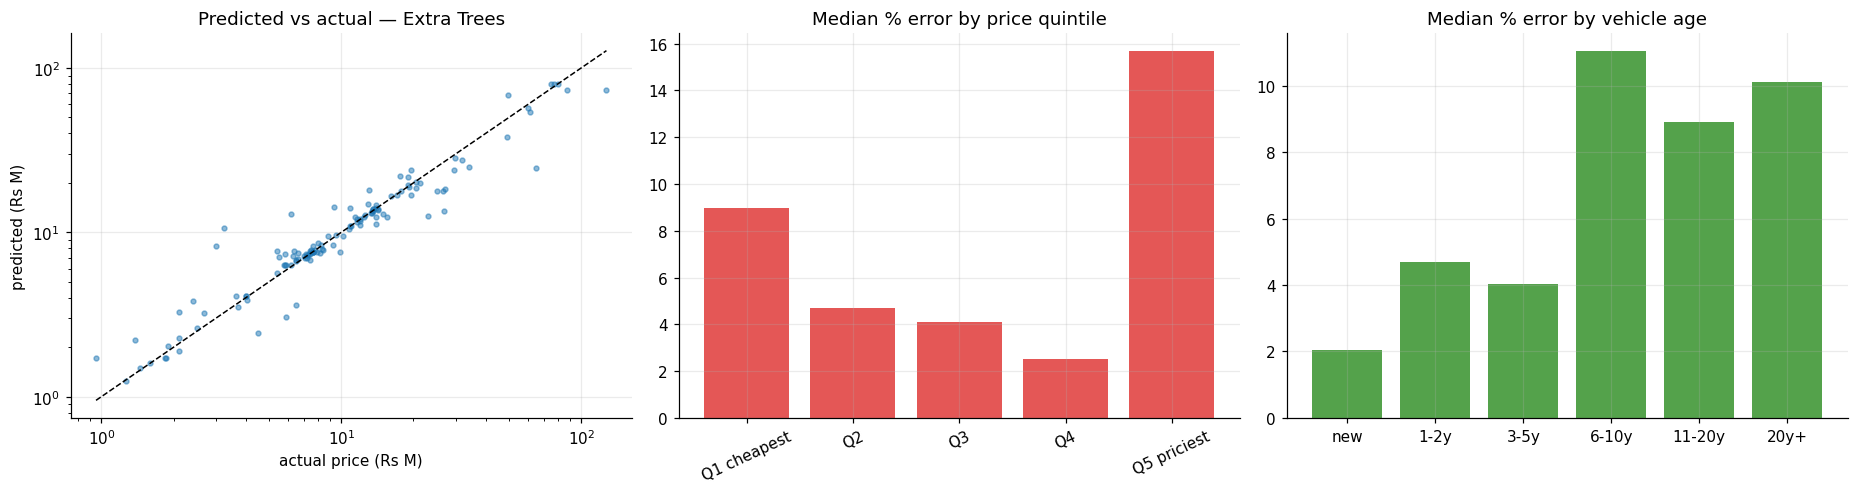

median |% error| overall: 6.8%   |   within ±10%: 64% of test cars   |   within ±20%: 75%


In [16]:
bp = preds[best_name]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].scatter(np.exp(y_test) / 1e6, np.exp(bp) / 1e6, s=10, alpha=.5)
lim = [np.exp(y_test).min() / 1e6, np.exp(y_test).max() / 1e6]; ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set(xscale="log", yscale="log", xlabel="actual price (Rs M)", ylabel="predicted (Rs M)", title=f"Predicted vs actual — {best_name}")
e = pd.DataFrame({"actual": np.exp(y_test.values), "pred": np.exp(bp), "age": X_test.age.values, "brand": X_test.brand.values})
e["ape"] = (e.pred - e.actual).abs() / e.actual * 100
e["band"] = pd.qcut(e.actual, 5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 priciest"])
b = e.groupby("band", observed=True).ape.median(); ax[1].bar(b.index.astype(str), b.values, color="#E45756"); ax[1].set(title="Median % error by price quintile"); ax[1].tick_params(axis="x", rotation=25)
e["age_bin"] = pd.cut(e.age, [-1, 0, 2, 5, 10, 20, 60], labels=["new", "1-2y", "3-5y", "6-10y", "11-20y", "20y+"])
a = e.groupby("age_bin", observed=True).ape.median(); ax[2].bar(a.index.astype(str), a.values, color="#54A24B"); ax[2].set(title="Median % error by vehicle age")
plt.tight_layout(); plt.show()
print(f"median |% error| overall: {e.ape.median():.1f}%   |   within ±10%: {(e.ape<=10).mean()*100:.0f}% of test cars   |   within ±20%: {(e.ape<=20).mean()*100:.0f}%")

**Interpretation** — For the best model the **median error is 6.8 %**, **64 % of test cars are within ±10 %** and **75 % within ±20 %**. The *mean* error (MAPE ≈ 17 %) is much higher than the median because of a heavy tail: a few expensive, rare or unusual listings (luxury SUVs, 1-of-a-kind imports) are badly mis-priced, and with so few comparable ads in the training data no ensemble can learn them. The predicted-vs-actual plot hugs the diagonal for mainstream cars and scatters at the top end. By price band the median error is ≈ 2.5–5 % for the middle three quintiles but **≈ 16 % for the priciest quintile** (and ≈ 9 % for the cheapest, where a Rs 0.5 M error is a large fraction). By age, **new cars are priced to ≈ 2 %** (dealers list near-identical prices for the same trim) whereas **6+-year-old cars have 9–11 % median error** — used-car prices depend on condition, trim and seller urgency that the listing fields do not capture.

## 8. Save artefacts for the dashboard
The Streamlit app (`app.py`) loads these files — nothing is re-trained at runtime.

In [17]:
def slug(n): return "".join(c.lower() if c.isalnum() else "_" for c in n).strip("_")

for n, est in fitted.items():
    joblib.dump(est, MODELS / f"{slug(n)}.joblib", compress=3)

results["slug"] = results.model.map(slug)
results.to_csv(MODELS / "metrics.csv", index=False)
imp.sort_values("importance", ascending=False).to_csv(MODELS / "importance.csv", index=False)

pd.DataFrame({"actual_price": np.exp(y_test.values), **{slug(n): np.exp(p) for n, p in preds.items()}}).to_csv(MODELS / "test_predictions.csv", index=False)

meta = {
    "best_model": best_name, "n_rows": int(len(df)), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "scraped": "2026-11-23", "current_year": CURRENT_YEAR,
    "brand_models": {b: sorted(g.model.dropna().unique().tolist()) for b, g in df.groupby("brand")},
    "brand_counts": df.brand.value_counts().to_dict(),
    "categories": {c: sorted(df[c].dropna().unique().tolist()) for c in ["body", "fuel", "transmission", "condition", "district"]},
    "ranges": {"year": [int(df.year.min()), CURRENT_YEAR], "mileage_km": [0, int(df.mileage_km.quantile(.99))],
               "engine_cc": [int(df.engine_cc.quantile(.01)), int(df.engine_cc.quantile(.99))]},
    "median_engine_by_brand_model": df.groupby("brand_model").engine_cc.median().dropna().round().astype(int).to_dict(),
    "rf_curve": [float(v) for v in rf_curve], "gb_test_curve": [float(v) for v in te_curve], "gb_train_curve": [float(v) for v in tr_curve],
}
json.dump(meta, open(MODELS / "meta.json", "w"))
print("saved", len(fitted), "models +", "metrics/importance/predictions/meta to", MODELS.resolve())

saved 12 models + metrics/importance/predictions/meta to /Users/udananimsara/Documents/Learn/uom-assginments/models


## 9. Conclusions & limitations

### Conclusions
1. **Ensembles work.** Every bagging, boosting and stacking model cut error by ~25–28 % versus a single decision tree and beat a Ridge baseline; the best reach **R² ≈ 0.92 on log-price** and a **median error of ≈ 7 %** on Sri Lankan car listings.
2. **No ensemble family wins decisively on this data.** Extra Trees, Stacking, XGBoost and CatBoost tie on the test set; Stacking, CatBoost and Gradient Boosting lead on cross-validation. For a ~600-row tabular problem the practical advice is: use a bagged/boosted tree model, tune lightly, and prefer the cheapest one (Extra Trees trains in ~1.5 s; Stacking takes ~2 min for no reliable gain).
3. **Why:** bagging attacks *variance* (error fell 0.43 → 0.34 → 0.29 as trees went 1 → 10 → 500); boosting attacks *bias* (test error flattens near round ~570 while train error keeps falling); stacking only helps when members err differently — here the tree models are 90–96 % correlated, so the gain is small.
4. **Hybridising needs a strong, diverse partner.** The ANN was diverse but weak on ~500 rows, so averaging it with Random Forest *hurt*; the stack, which learns weights, was safe.
5. **Price drivers:** market segment (transmission / engine / body / brand) and age dominate; mileage and fuel matter less once those are known.

### Limitations & next steps
* **Small sample:** 633 cleaned ads (≈ 1/17 of ikman's ~10.8 k car ads) — scraping was limited by the site's response speed. The test set has only 127 cars, so differences < ~0.03 RMSE are noise. More data would favour boosting/stacking and the ANN.
* **Asking prices, one day (23 Nov 2026):** negotiated sale prices are lower; no seasonality or trend is captured.
* **Excluded:** vintage cars (pre-1985) and a handful of extreme prices; only 6 electric cars, so EV predictions are unreliable. Rare models are predicted from brand-level patterns.
* **Not done:** heavy hyper-parameter search, repeated CV for significance tests, ikman text features (description, trim), location at city level.
* Next: scrape more pages over several weeks, add Optuna tuning, quantile/conformal models for proper price intervals.